# 13주차 · 인공지능의 원리와 문제해결

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phyzikyh/computing/blob/main/%EA%B0%95%EC%9D%98%EA%B5%90%EC%9E%AC/week13_lecture.ipynb)

## 자주 사용하는 함수와 메서드

`slot`은 날짜·매장·시간대 하나가 한 행인 표입니다. 이 표의 주문 건수와 직원 수를 입력으로, 평균 대기시간을 예측합니다. 아래 예시는 각 도구의 사용 형태를 보여 줍니다.

| 구분 | 함수·메서드 | 하는 일 | 사용 예시 |
|---|---|---|---|
| 자료 나누기 | `train_test_split()` | 자료를 학습용과 평가용으로 무작위로 나눕니다. | `train_test_split(X, y, test_size=0.2, random_state=0)` |
| 선형 회귀 모델 | `LinearRegression()` | 직선의 식으로 숫자를 예측하는 모델을 만듭니다. | `model = LinearRegression()` |
| 의사결정나무 모델 | `DecisionTreeRegressor()` | 질문을 이어 가며 숫자를 예측하는 모델을 만듭니다. | `DecisionTreeRegressor(max_depth=3)` |
| 랜덤 포레스트 모델 | `RandomForestRegressor()` | 나무 여러 개의 예측을 평균해 숫자를 예측하는 모델을 만듭니다. | `RandomForestRegressor(n_estimators=100)` |
| 학습 | `fit()` | 학습용 입력과 정답으로 모델 안의 규칙(직선의 기울기와 절편 등)을 계산합니다. | `model.fit(X_train, y_train)` |
| 예측 | `predict()` | 학습된 모델에 입력을 넣어 예측값을 계산합니다. | `model.predict(X_test)` |
| 기울기와 절편 | `coef_`, `intercept_` | 선형 회귀가 학습한 식의 값입니다. | `model.coef_`, `model.intercept_` |
| 나무 그림 | `plot_tree()` | 나무가 학습한 질문과 예측값을 그림으로 보여 줍니다. | `plot_tree(tree, feature_names=names)` |
| 평균 오차 | `mean_absolute_error()` | 예측값과 실제값 차이의 절댓값 평균을 구합니다. | `mean_absolute_error(y_test, predicted)` |
| 묶어서 계산 | `groupby()` | 기준이 같은 행끼리 묶어 개수나 평균을 계산합니다. | `data.groupby(keys)["wait_minutes"].mean()` |
| 점 그래프 | `plt.scatter()` | 두 값의 관계를 점으로 그립니다. | `plt.scatter(x, y, s=8, alpha=0.4)` |
| 선 그래프 | `plt.plot()` | 점들을 선으로 이어 그립니다. | `plt.plot(x, y)` |
| 정렬 | `sort_values()` | 지정한 열의 값을 기준으로 행을 정렬합니다. | `check.sort_values("오차", ascending=False)` |
| 막대 그래프 | `plt.hist()` | 값을 구간으로 나누어 구간마다 개수를 막대로 그립니다. | `plt.hist(values, bins=15)` |
| 그래프 꾸미기 | `plt.title()`, `plt.xlabel()`, `plt.ylabel()`, `plt.legend()` | 제목, 축 이름, 범례를 넣습니다. | `plt.title("제목")` |

`import 이름`은 도구 모음을 불러오고, `as 줄임말`은 짧은 이름을 붙입니다.

- `numpy`(`np`)는 숫자 계산, `pandas`(`pd`)는 표 다루기, `matplotlib.pyplot`(`plt`)은 그래프 그리기에 씁니다.
- `from sklearn... import 함수이름`은 머신러닝 도구 모음 scikit-learn에서 필요한 함수만 가져옵니다. 위 표의 함수들이 여기에 들어 있습니다.
- `fonts`와 `for` 반복문은 컴퓨터에 설치된 한글 글꼴을 찾아 그래프의 글꼴로 지정합니다. 지정하지 않으면 그래프의 한글이 깨집니다.
- `plt.rcParams[...]`는 그래프의 기본 설정(글꼴, 그림 크기, 위·오른쪽 테두리 숨김)입니다.
- `pd.set_option("display.max_columns", 20)`은 표를 출력할 때 최대 20개 열까지 보여 주는 설정입니다.

Colab에서는 한글 글꼴이 기본으로 없으므로 다음 두 줄을 **먼저 실행한 뒤 런타임을 다시 시작**합니다.

```
!apt-get -qq -y install fonts-nanum
!fc-cache -fv
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

fonts = {font.name for font in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 20)

## 인공지능과 머신러닝

**인공지능**은 예측, 구분, 판단처럼 지능이 필요한 일을 컴퓨터가 수행하도록 만드는 기술입니다. 스팸 메일 걸러 내기, 지도 앱의 도착 시간 안내, 영상 서비스의 추천이 인공지능이 쓰인 예입니다.

**머신러닝**은 인공지능을 구현하는 방법의 하나로, 과거의 자료에서 입력과 결과 사이의 **규칙을 학습**합니다. 학습한 규칙을 담고 있는 것을 **모델**이라고 하며, 모델에 입력을 넣으면 결과(예측)가 나옵니다.

머신러닝은 학습에 쓰는 자료에 따라 세 가지로 나눕니다. **지도학습**은 입력과 정답이 짝지어진 자료로 입력에서 정답을 예측하는 규칙을 학습하고, **비지도학습**은 정답 없이 입력만으로 자료의 구조나 비슷한 집단을 찾고, **강화학습**은 행동에 대한 보상을 받으며 보상을 최대화하는 행동 전략을 학습합니다. 지도학습에서 맞히려는 값이 숫자이면 **회귀**, 범주이면 **분류**라고 합니다. 이번 자료는 카페의 한 매장에서 한 시간 동안의 **주문 건수와 직원 수**(입력)로 그 시간의 **평균 대기시간**(숫자)을 예측하는 회귀 문제를 다룹니다. 같은 문제를 선형 회귀, 의사결정나무, 랜덤 포레스트라는 세 가지 모델로 풀어 결과를 비교합니다.

## 머신러닝의 절차

머신러닝은 문제의 종류와 상관없이 다음 여섯 단계로 진행합니다. 이 순서는 머신러닝 프로젝트의 표준 점검 목록(Géron, *Hands-On Machine Learning*, Appendix A)과 scikit-learn의 사용 흐름(자료 분할, `fit`, `predict`, 평가)을 기준으로 정리한 것입니다. 이 자료는 아래 순서대로 진행합니다.

**1 문제 정의 → 2 자료 준비 → 3 모델 학습 → 4 모델 평가 → 5 성능 개선 → 6 예측과 활용**

5단계에서 성능이 부족하면 입력·모델·설정을 바꾸어 3단계로 돌아가 반복합니다.

| 단계 | 하는 일 | 이번 자료에서 쓰는 코드 |
|---|---|---|
| 1단계 문제 정의 | 맞힐 값(목표 변수), 사용할 값(입력 변수), 문제의 종류(회귀), 평가 지표를 정합니다. | 표에서 열 선택 |
| 2단계 자료 준비 | 분석 단위에 맞는 표를 만들고, 자료를 학습용과 평가용으로 나눕니다. | `groupby()`, `train_test_split()` |
| 3단계 모델 학습 | 모델을 선택하고 학습용 자료로 규칙을 학습합니다. | `LinearRegression()`, `fit()` |
| 4단계 모델 평가 | 평가용 입력으로 예측하고, 평가용 정답과 비교해 오차를 계산합니다. | `predict()`, `mean_absolute_error()` |
| 5단계 성능 개선 | 입력 변수, 모델, 설정을 바꿔 3~4단계를 반복하고 평가용 오차를 비교합니다. | 입력 추가, 모델 교체, `max_depth` |
| 6단계 예측과 활용 | 선택한 모델에 정답을 모르는 새 입력을 넣어 예측하고 결과를 해석합니다. | `predict()` |

학습용 자료와 평가용 자료는 역할이 다릅니다. 모델은 학습용 자료로만 학습하고, 학습에 쓰지 않은 평가용 자료로 성능을 확인합니다.

### 용어 정리

| 용어 | 뜻 | 이번 자료의 예 |
|---|---|---|
| 입력 변수 | 모델에 넣는 값 | 주문 건수, 직원 수 |
| 목표 변수 | 모델이 맞히려는 값(정답) | 평균 대기시간 |
| 모델 | 자료에서 학습한 규칙을 담은 것 | 직선의 식, 의사결정나무, 랜덤 포레스트 |
| 학습 | 학습용 자료에서 규칙을 계산하는 과정 | `fit()` |
| 예측 | 입력으로 결과를 계산하는 것 | `predict()` |
| 평가 | 예측이 실제와 얼마나 가까운지 확인하는 것 | 평균 절대 오차 |
| 학습용 자료 | 학습에 쓰는 자료 | 전체의 80% |
| 평가용 자료 | 학습에 쓰지 않고 성능을 확인하는 자료 | 전체의 20% |
| 오차 | 예측값과 실제값의 차이 | 예측 6분, 실제 8분이면 오차 2분 |
| 과적합 | 학습용 자료에만 지나치게 맞아 새 자료에서 틀리는 상태 | 깊이 제한이 없는 나무 |

## 1단계 문제 정의

앞에서는 주문 건수와 평균 대기시간이 함께 높아지는 관계를 확인했습니다. 이 관계를 새로운 상황에 적용할 수 있는 모델로 만듭니다. 문제를 다음과 같이 정의합니다.

| 항목 | 내용 |
|---|---|
| 질문 | 한 매장에서 한 시간의 주문 건수와 직원 수를 알 때, 평균 대기시간은 몇 분인가? |
| 문제의 종류 | 맞히려는 값이 숫자이므로 회귀 |
| 입력 변수 | 주문 건수(`orders`), 직원 수(`staff`) |
| 목표 변수 | 평균 대기시간(`wait`, 단위 분) |
| 평가 지표 | 평균 절대 오차(예측값과 실제값 차이의 절댓값의 평균) |

과거 기록의 실제 주문 건수로 관계를 학습한 뒤, 활용할 때는 예상 주문 건수를 입력으로 넣습니다. 예상 주문량이 틀리면 예측도 달라집니다. 또 이 모델이 맞히는 것은 한 시간대의 평균 대기시간이며, 개별 손님이 기다릴 시간이 아닙니다.

주문 한 건이 한 행인 원자료로는 "한 시간의 주문 건수"를 알 수 없습니다. 예측하려는 단위인 매장·날짜·시간대 하나가 한 행이 되도록 표를 만드는 것이 다음 단계입니다.

## 2단계 자료 준비

### 카페 주문 자료 불러오기

주문 기록 파일을 찾습니다. 컴퓨터에 없으면 인터넷에서 내려받습니다.

- `find_file(name)`은 `def`로 직접 만든 **함수**입니다. 파일 이름으로 현재 폴더와 상위 폴더들을 차례로 찾아, 찾으면 파일 경로를, 못 찾으면 `None`(없음)을 돌려줍니다.
- `source = csv_path if csv_path else URL`은 파일을 찾았으면 그 경로를, 못 찾았으면 인터넷 주소를 `source`에 담습니다.

In [2]:
URL = "https://raw.githubusercontent.com/phyzikyh/computing/main/%EA%B0%95%EC%9D%98%EA%B5%90%EC%9E%AC/data/week11_cafe_orders.csv"


def find_file(name):
    starts = [Path.cwd()]
    notebook = globals().get("__vsc_ipynb_file__")
    if notebook:
        starts.insert(0, Path(notebook).parent)
    for start in starts:
        for folder in [start, *start.parents][:4]:
            for sub in ["", "data", "강의교재/data"]:
                path = folder / sub / name
                if path.exists():
                    return path
    return None


csv_path = find_file("week11_cafe_orders.csv")
source = csv_path if csv_path else URL

- `pd.read_csv(source, encoding="utf-8-sig")`는 CSV 파일을 표로 읽어 `raw`에 저장합니다. `encoding`은 한글이 깨지지 않게 하는 글자 방식 설정입니다.
- `raw.head(4)`는 표의 앞 4행을 보여 줍니다.

In [3]:
raw = pd.read_csv(source, encoding="utf-8-sig")
raw.head(4)

,order_id,order_date,order_time,weekday,order_hour,store_location,menu_name,order_count,unit_price,sales_amount,wait_minutes,payment_method,weather,event_day,staff_count
0,2526,2026-03-02,09:01:32,월,9,공학관점,아메리카노,1,2500,2500,3.3,NaN,비,행사,3
1,2015,2026-03-02,09:01:51,월,9,학생회관점,카페라테,1,3500,3500,9.0,NaN,비,행사,2
2,2289,2026-03-02,09:01:56,월,9,도서관점,바닐라라테,2,4000,8000,5.2,카드,NaN,행사,3
3,2527,2026-03-02,09:04:47,월,9,공학관점,바닐라라테,1,4000,4000,4.0,NaN,비,행사,3


계산에는 같은 주문이 중복되지 않고, 수량이 기록 범위 안에 있는 행을 사용합니다. 이 코드는 분석할 표 `data`를 준비하며 원본 `raw`는 보존합니다.

- `drop_duplicates()`는 완전히 같은 행을 하나만 남깁니다.
- `order_count`가 1~6인 행만 남깁니다.
- 대기시간이 음수인 행은 기록 오류이므로 비어 있는 값(`np.nan`)으로 바꿉니다.
- `pd.to_datetime()`은 날짜 글자를 날짜 형식으로 바꿉니다.

- `data[(조건 1) & (조건 2)]`는 두 조건을 모두 만족하는 행만 골라냅니다. `&`는 "그리고"를 뜻합니다.
- `.copy()`는 표를 복사해 원본과 분리합니다.
- `data.loc[조건, "열 이름"] = 값`은 조건을 만족하는 행의 해당 열 값을 바꿉니다.
- `len(data)`는 행의 개수이고, `print()`는 괄호 안의 값을 화면에 출력합니다.

In [4]:
data = raw.drop_duplicates().copy()
data = data[(data["order_count"] >= 1) & (data["order_count"] <= 6)]
data = data.copy()
data.loc[data["wait_minutes"] < 0, "wait_minutes"] = np.nan
data["order_date"] = pd.to_datetime(data["order_date"])
print("주문 기록:", len(data), "건")

주문 기록: 103449 건


### 시간대별 자료표 만들기

날짜·매장·시간대 하나가 한 행인 표 `slot`을 만듭니다. 한 행에는 그 시간 동안의 주문 건수, 평균 대기시간, 직원 수가 들어 있습니다.

`groupby(keys)`는 날짜·매장·시간대가 같은 주문끼리 묶습니다. 묶음마다 주문 번호의 개수(`count()`)를 세면 주문 건수, 대기시간의 평균(`mean()`)을 구하면 평균 대기시간이 됩니다.

- `keys`는 묶는 기준이 되는 열 이름의 목록입니다.
- `data.groupby(keys)["order_id"].count()`는 묶음마다 `order_id`의 개수를 셉니다. 한 시간 동안의 주문 건수입니다.
- `data.groupby(keys)["wait_minutes"].mean()`은 묶음마다 대기시간의 평균을 구합니다.

In [5]:
keys = ["order_date", "store_location", "order_hour"]
slot_orders = data.groupby(keys)["order_id"].count()
slot_wait = data.groupby(keys)["wait_minutes"].mean()
slot_staff = data.groupby(keys)["staff_count"].mean()

- `pd.DataFrame({"열 이름": 값, ...})`은 여러 값을 열로 묶어 표를 만듭니다.
- `reset_index()`는 묶는 기준이었던 날짜·매장·시간대를 일반 열로 되돌립니다.
- `slot.head()`는 표의 앞 5행을 보여 줍니다.

In [6]:
slot = pd.DataFrame({
    "orders": slot_orders, "wait": slot_wait, "staff": slot_staff
}).reset_index()
slot.head()

,order_date,store_location,order_hour,orders,wait,staff
0,2026-03-02,공학관점,9,16,4.520000,3.0
1,2026-03-02,공학관점,10,13,4.969231,3.0
2,2026-03-02,공학관점,11,20,5.478947,3.0
3,2026-03-02,공학관점,12,52,9.609615,4.0
4,2026-03-02,공학관점,13,51,7.715686,4.0


`describe()`는 열마다 개수(`count`), 평균(`mean`), 최솟값(`min`), 최댓값(`max`) 등을 요약해 줍니다. `len(slot)`은 행의 개수, `.round(2)`는 소수 둘째 자리까지 반올림입니다.

In [7]:
print("시간대 수:", len(slot))
slot[["orders", "wait", "staff"]].describe().round(2)

시간대 수: 3900


,orders,wait,staff
count,3900.00,3900.00,3900.00
mean,26.53,5.27,3.09
std,15.39,1.82,0.50
min,4.00,2.28,2.00
25%,16.00,3.97,3.00
50%,22.00,4.50,3.00
75%,32.00,6.55,3.00
max,120.00,18.77,4.00


### 산점도로 관계 확인하기

주문 건수를 가로축, 평균 대기시간을 세로축으로 시간대마다 점을 하나씩 찍어 관계를 확인합니다.

- `plt.scatter(가로값, 세로값, ...)`은 점 그래프를 그립니다. `s`는 점의 크기, `alpha`는 투명도(0~1), `color`는 색입니다.
- `plt.title()`, `plt.xlabel()`, `plt.ylabel()`은 제목, 가로축 이름, 세로축 이름을 정합니다.
- `plt.tight_layout()`은 글자가 잘리지 않도록 여백을, `plt.show()`는 그림을 화면에 나타냅니다.

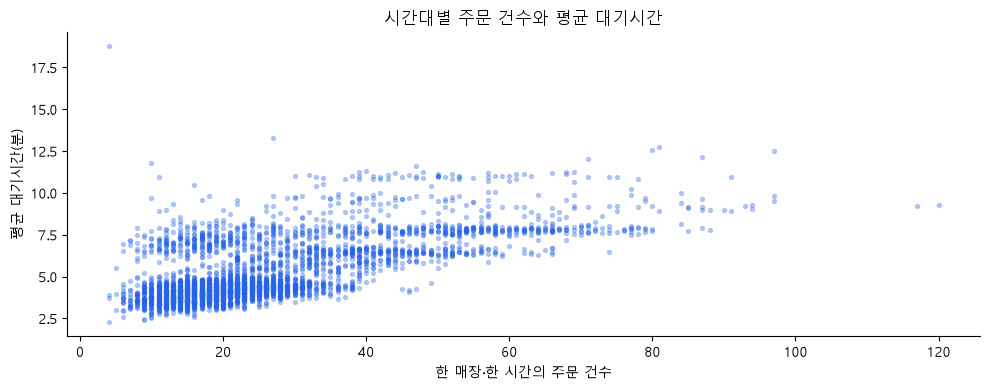

In [8]:
plt.scatter(slot["orders"], slot["wait"], s=8, alpha=0.3, color="#2563eb")
plt.title("시간대별 주문 건수와 평균 대기시간")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.tight_layout()
plt.show()

점은 오른쪽으로 갈수록 대체로 위로 올라갑니다. 주문이 많은 시간대일수록 평균 대기시간이 긴 경향입니다. 그러나 주문 건수가 같아도 점들의 높이가 크게 다릅니다. 주문 건수 하나만으로는 평균 대기시간을 정확히 맞히기 어렵고, 직원 수 같은 다른 정보가 필요해 보입니다.

### 입력 변수와 목표 변수 선택하기

모델에 넣는 값을 **입력 변수**, 모델이 맞히려는 값을 **목표 변수**라고 합니다. 입력 변수는 주문 건수 `orders`와 직원 수 `staff`이고, 목표 변수는 평균 대기시간 `wait`입니다.

관례로 입력 변수는 대문자 `X`, 목표 변수는 소문자 `y`로 씁니다. `X`는 열이 여러 개인 표이므로 열 이름을 이중 대괄호(`[["orders", "staff"]]`)로 선택합니다.

- `slot[["orders", "staff"]]`는 두 열을 골라 표로 만들고, `slot["wait"]`는 열 하나를 골라 값의 나열로 만듭니다.

In [9]:
X = slot[["orders", "staff"]]
y = slot["wait"]
X.head()

,orders,staff
0,16,3.0
1,13,3.0
2,20,3.0
3,52,4.0
4,51,4.0


### 학습용 자료와 평가용 자료로 나누기

모델은 학습용 자료로 규칙을 학습하고, 학습에 쓰지 않은 평가용 자료로 성능을 확인합니다. 학습한 자료로 다시 점수를 내면 모델이 자료를 외웠는지, 새로운 입력에도 맞히는지 구분할 수 없기 때문입니다. 자료의 80%는 학습용, 20%는 평가용으로 나눕니다.

`random_state`를 고정하면 매번 같은 방식으로 나뉩니다. [scikit-learn의 train_test_split 설명](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

`train_test_split()`은 입력 `X`와 정답 `y`를 같은 행끼리 짝을 지어 나눕니다. 결과로 4개가 나오며, 코드의 왼쪽에 쓴 이름 순서대로 받습니다.

| 이름 | 내용 |
|---|---|
| `X_train`, `X_test` | 학습용 입력, 평가용 입력 |
| `y_train`, `y_test` | 학습용 평균 대기시간, 평가용 평균 대기시간(정답) |

`test_size=0.2`는 20%를 평가용으로 떼어 놓는다는 뜻입니다.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
print("학습용:", len(X_train), "개 / 평가용:", len(X_test), "개")

학습용: 3120 개 / 평가용: 780 개


- `y_train.mean()`과 `y_test.mean()`은 학습용과 평가용의 평균 대기시간입니다. 두 값이 비슷하면 한쪽에 긴 대기가 몰리지 않고 고르게 나뉜 것입니다.

In [11]:
print("학습용 평균 대기시간:", round(y_train.mean(), 2), "분")
print("평가용 평균 대기시간:", round(y_test.mean(), 2), "분")

학습용 평균 대기시간: 5.28 분
평가용 평균 대기시간: 5.22 분


학습용의 평균 대기시간 5.28분과 평가용의 평균 대기시간 5.22분이 비슷합니다. 두 자료를 점으로 나타내 확인합니다.

- `plt.scatter()`를 두 번 부르면 두 점 그래프가 한 그림에 겹쳐 그려집니다. 학습용은 파란색, 평가용은 주황색입니다.
- `plt.title()`, `plt.xlabel()`, `plt.ylabel()`, `plt.legend()`, `plt.tight_layout()`, `plt.show()`는 앞의 그래프와 같은 역할입니다.

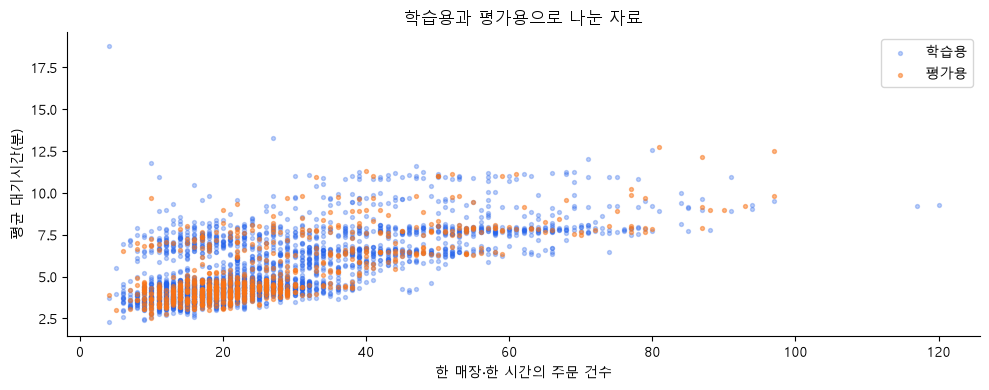

In [12]:
plt.scatter(X_train["orders"], y_train, s=8, alpha=0.3, color="#2563eb", label="학습용")
plt.scatter(X_test["orders"], y_test, s=8, alpha=0.5, color="#f97316", label="평가용")
plt.title("학습용과 평가용으로 나눈 자료")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.legend()
plt.tight_layout()
plt.show()

파란 점이 학습용(3,120개), 주황 점이 평가용(780개)입니다. 평가용 점이 특정 구간에 몰리지 않고 학습용 점 사이에 고르게 섞여 있습니다. 모델은 파란 점만 보고 규칙을 학습하고, 주황 점은 4단계에서 성능을 확인할 때만 사용합니다.

## 3단계 모델 학습

### 선형 회귀 모델

**선형 회귀**는 입력과 목표 변수 사이에 직선 관계가 있다고 보고, 다음 식으로 예측하는 모델입니다.

**예측값 = 절편 + 기울기 × 입력**

학습은 학습용 자료의 점들에 가장 가까운 직선, 곧 예측값과 실제값의 차이(오차)의 제곱을 모두 더한 값이 가장 작아지는 기울기와 절편을 찾는 일입니다. 먼저 입력을 주문 건수 하나로 합니다.

### fit()으로 학습하기

**학습은 `fit()` 함수가 수행합니다.** `fit(입력, 정답)`에 학습용 입력과 학습용 정답을 주면, `fit()`이 오차가 가장 작아지는 기울기와 절편을 계산해 모델 안에 저장합니다. `fit()`을 실행하기 전의 모델은 값이 없는 빈 모델이어서 예측할 수 없고, `fit()`이 끝난 뒤에야 `predict()`로 예측할 수 있습니다. 모델의 종류가 달라도 학습은 `fit()`으로 합니다. 선형 회귀는 직선의 기울기와 절편을, 의사결정나무는 질문과 기준값을, 랜덤 포레스트는 여러 나무의 질문과 기준값을 저장합니다.

- `LinearRegression()`은 선형 회귀 모델을 만듭니다. 아직 `fit()`을 하지 않은 빈 모델입니다.
- `model_one.fit(입력, 정답)`이 학습입니다. `X_train[["orders"]]`는 주문 건수 열 하나만 표로 골라 입력으로 줍니다. 평가용 자료는 넣지 않습니다.

In [13]:
model_one = LinearRegression()
model_one.fit(X_train[["orders"]], y_train)
print("학습을 마쳤습니다.")

학습을 마쳤습니다.


- `fit()`이 끝나면 학습한 직선의 값이 모델에 저장됩니다. `model_one.coef_`는 기울기를 담은 목록이라 `[0]`으로 첫 번째 값을 꺼내고, `model_one.intercept_`는 절편입니다.

In [14]:
slope = model_one.coef_[0]
intercept = model_one.intercept_
print("기울기:", round(slope, 4))
print("절편:", round(intercept, 2))

기울기: 0.0786
절편: 3.2


`fit()`이 학습한 식은 **평균 대기시간 = 3.20 + 0.079 × 주문 건수**입니다. 기울기 0.079은 한 시간의 주문이 1건 늘 때 평균 대기시간이 약 0.08분 길어지는 경향을 뜻합니다. 절편은 주문이 0건일 때의 식의 값이며, 실제로 주문이 하나도 없는 시간대의 대기시간을 뜻하지는 않습니다.

학습한 모델에 새로운 입력을 주면 예측값을 계산합니다(`predict()`). 주문이 20건, 50건, 80건인 시간대의 평균 대기시간을 예측합니다.

- `pd.DataFrame({"orders": [20, 50, 80]})`는 주문 건수가 20, 50, 80인 입력 표를 만듭니다.
- `zip(a, b)`는 두 목록을 짝지어 하나씩 꺼내고, `for` 반복문이 한 쌍마다 `print()`를 실행합니다.

In [15]:
new_orders = pd.DataFrame({"orders": [20, 50, 80]})
predicted_wait = model_one.predict(new_orders)
for orders, wait in zip(new_orders["orders"], predicted_wait):
    print(orders, "건 → 예측 평균 대기시간", round(wait, 1), "분")

20 건 → 예측 평균 대기시간 4.8 분
50 건 → 예측 평균 대기시간 7.1 분
80 건 → 예측 평균 대기시간 9.5 분


주문이 많아질수록 예측 평균 대기시간이 길어집니다(20건 4.8분, 50건 7.1분, 80건 9.5분). 모델은 학습용 자료의 주문 건수 범위 안에서 학습한 식이므로, 자료에 없던 범위의 값은 믿기 어렵습니다.

학습용 자료의 점 위에 학습한 직선을 그립니다. 직선은 주문 건수의 최솟값부터 최댓값까지의 예측값을 이은 것입니다.

- `X_train["orders"].min()`과 `.max()`는 주문 건수의 최솟값과 최댓값입니다. 이 두 지점의 예측값을 구해 이으면 직선이 됩니다.
- `plt.plot(가로값, 세로값, ...)`은 점들을 선으로 잇는 그래프를 그립니다. `linewidth`는 선의 굵기입니다.
- `plt.scatter()`와 `plt.plot()`을 차례로 부르면 한 그림에 겹쳐 그려집니다.

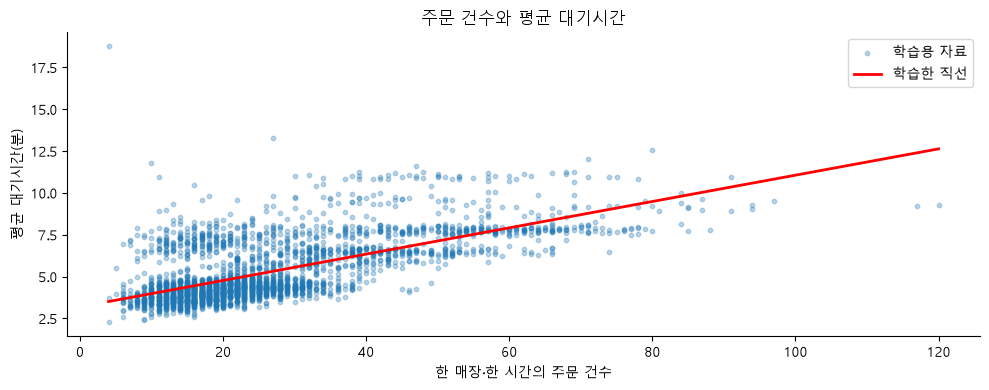

In [16]:
line_x = pd.DataFrame({"orders": [X_train["orders"].min(), X_train["orders"].max()]})
line_y = model_one.predict(line_x)

plt.scatter(X_train["orders"], y_train, s=10, alpha=0.3, label="학습용 자료")
plt.plot(line_x["orders"], line_y, color="red", linewidth=2, label="학습한 직선")
plt.title("주문 건수와 평균 대기시간")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.legend()
plt.tight_layout()
plt.show()

직선은 점들이 전체적으로 오르는 방향을 따라갑니다. 주문 건수가 같아도 점들의 높이가 다른 것은 직선 하나로는 설명되지 않는 부분입니다. 또 주문이 60건을 넘는 구간에서는 점들이 직선보다 낮게 놓여, 직선이 평균 대기시간을 실제보다 길게 예측합니다. 이 점은 5단계에서 모델 종류를 바꾸어 비교할 때 다시 확인합니다.

## 4단계 모델 평가

### 평가용 자료로 예측하기

학습한 직선이 좋은지 판단하려면 모델이 학습에 쓰지 않은 평가용 자료로 예측하고, 그 결과를 평가용 정답과 비교합니다. `predict()`는 입력만 주면 예측값을 계산합니다. 평가용 정답 `y_test`는 모델에 주지 않고, 계산된 예측값과 나중에 비교합니다.

예측이 얼마나 틀렸는지는 **평균 절대 오차**로 나타냅니다. 시간대마다 예측값과 실제값의 차이를 구해 절댓값의 평균을 낸 것으로, 단위는 분입니다.

- `model_one.predict(X_test[["orders"]])`는 평가용 입력 전체의 예측값을 계산합니다.
- `mean_absolute_error(y_test, predicted_test)`는 예측값과 평가용 정답의 평균 절대 오차를 구합니다.

In [17]:
predicted_test = model_one.predict(X_test[["orders"]])
model_one_error = mean_absolute_error(y_test, predicted_test)
print("평균 절대 오차:", round(model_one_error, 2), "분")

평균 절대 오차: 0.97 분


평가용 자료에서 예측값과 실제값은 평균 0.97분 차이가 납니다. 평가용 시간대의 평균 대기시간이 5.2분이므로, 예측은 정확한 값이 아니라 대략적인 수준으로 해석합니다. 이 값은 5단계에서 입력과 모델을 바꿀 때 비교의 출발점이 됩니다.

평균 절대 오차가 어떻게 계산되는지 평가용 자료의 처음 5개 시간대로 확인합니다. 오차는 실제값과 예측값의 차이에서 부호를 무시하고 크기만 본 값입니다(절댓값).

- `pd.DataFrame({...})`는 열 이름과 값을 짝지어 표를 만듭니다.
- `check["오차"] = ...`는 새 열을 추가합니다. `.abs()`는 절댓값입니다.
- `check.head(5)`는 앞 5행을 보여 주고, `.round(2)`는 소수 둘째 자리까지 나타냅니다.

In [18]:
check = pd.DataFrame({
    "주문 건수": X_test["orders"],
    "실제 대기시간": y_test,
    "예측 대기시간": predicted_test,
})
check["오차"] = (check["실제 대기시간"] - check["예측 대기시간"]).abs()
check.head(5).round(2)

,주문 건수,실제 대기시간,예측 대기시간,오차
1951,13,3.49,4.22,0.73
1550,12,3.24,4.14,0.91
31,14,6.61,4.30,2.31
3171,20,3.80,4.77,0.97
1044,55,6.30,7.52,1.23


이렇게 시간대마다 구한 오차를 평가용 자료 전체(780개)에서 평균한 값이 앞에서 계산한 평균 절대 오차입니다.

- `check["오차"].mean()`은 오차 열 전체의 평균입니다.

In [19]:
print("평균 절대 오차:", round(check["오차"].mean(), 2), "분")

평균 절대 오차: 0.97 분


`mean_absolute_error()`로 구한 값과 같습니다.

## 5단계 성능 개선

평가 결과를 읽고 성능을 높일 방법을 찾습니다. 바꿀 수 있는 것은 **입력 변수**, **모델의 종류**, **모델의 설정**입니다. 하나를 바꾼 뒤 3~4단계를 다시 하고, 같은 평가용 자료와 같은 평균 절대 오차로 이전 결과와 비교합니다.

### 입력 변수 추가하기

대기시간은 주문 건수뿐 아니라 직원 수에도 영향을 받을 수 있습니다. 입력을 주문 건수와 직원 수 두 개로 늘려 같은 방식으로 학습하고 평가합니다.

- 입력이 두 개이므로 `X_train` 전체를 `fit()`에 줍니다. 계수도 입력마다 하나씩, 두 개가 나옵니다.
- `zip(X_train.columns, model_two.coef_)`는 입력 열 이름과 그 열의 계수를 짝지어 꺼냅니다. `X_train.columns`는 표의 열 이름 목록입니다.

In [20]:
model_two = LinearRegression()
model_two.fit(X_train, y_train)

for name, value in zip(X_train.columns, model_two.coef_):
    print(name, "의 계수:", round(value, 3))
print("절편:", round(model_two.intercept_, 2))

orders 의 계수: 0.104
staff 의 계수: -1.25
절편: 6.38


- `model_two.predict(X_test)`는 두 입력으로 평가용 예측값을 계산하고, `mean_absolute_error()`로 평균 오차를 구해 주문 건수만 쓴 직선의 결과와 비교합니다.

In [21]:
model_two_error = mean_absolute_error(y_test, model_two.predict(X_test))
print("주문 건수만 사용:", round(model_one_error, 2), "분")
print("주문 건수와 직원 수 사용:", round(model_two_error, 2), "분")

주문 건수만 사용: 0.97 분
주문 건수와 직원 수 사용: 0.93 분


직원 수를 더하면 평균 오차가 0.97분에서 0.93분으로 줄었습니다. 각 계수는 **다른 입력이 같을 때** 그 입력이 1 늘면 예측값이 얼마나 달라지는지를 나타냅니다. 주문 건수가 같을 때 직원이 1명 늘면 예측 평균 대기시간이 약 1.25분 짧아집니다.

계수는 자료에서 함께 움직이는 정도를 요약한 것이므로, 직원을 늘리면 대기시간이 계수만큼 줄어든다고 확정하지는 못합니다. 이 자료에서 직원 4명인 시간대는 평균 주문이 51건, 3명인 시간대는 22건으로, 직원이 많은 시간대는 주문도 많습니다. 입력 사이에 얽힌 조건이 있으면 해석이 달라질 수 있습니다.

### 의사결정나무의 원리

선형 회귀는 입력과 정답이 직선 관계라고 가정합니다. 자료가 직선이 아닌 모양이면 다른 방식의 모델이 더 잘 맞을 수 있습니다. 입력(`X`), 정답(`y`), 학습용·평가용 자료는 그대로 두고 모델만 바꾸어 비교합니다. 모델을 바꿔도 `fit()`으로 학습하고 `predict()`로 예측하는 사용법은 같습니다.

**의사결정나무**는 스무고개처럼 예·아니오로 답하는 질문을 하나씩 던져 자료를 나누는 모델입니다. 동물을 구분하는 나무를 보면 구조를 쉽게 알 수 있습니다. "날개가 있나요?"에 예이면 왼쪽으로, 아니오이면 오른쪽으로 갑니다. 이렇게 질문에 답하며 내려가다 맨 아래 칸에 도착하면, 그 칸이 결과입니다.

- 날개가 있나요?
  - 예 → 날 수 있나요?
    - 예 → **독수리**
    - 아니오 → **펭귄**
  - 아니오 → 지느러미가 있나요?
    - 예 → **돌고래**
    - 아니오 → **곰**

들여쓴 줄 하나가 질문 하나의 답입니다. 질문에 답하며 아래로 내려가다 굵은 글씨(결과)에 도착하면 멈춥니다.

숫자를 예측하는 회귀에도 같은 구조를 씁니다. 다른 점은 맨 아래 칸의 내용입니다. 결과 이름 대신 **그 칸에 도착한 학습용 시간대들의 평균 대기시간**이 적혀 있고, 이 평균이 예측값입니다. 질문은 "주문이 32건 이하인가요?"처럼 입력 변수 하나와 기준값으로 만듭니다.

다음은 학습용 자료로 질문을 두 번까지 이어 가도록 학습한 나무입니다. `DecisionTreeRegressor(max_depth=2)`로 만들고 `fit()`으로 학습했습니다.

- 주문 건수가 32건 이하인가요?
  - 예 → 직원 수가 2명 이하인가요?
    - 예 → **평균 7.3분** (시간대 254개)
    - 아니오 → **평균 4.3분** (시간대 2,116개)
  - 아니오 → 주문 건수가 41건 이하인가요?
    - 예 → **평균 6.5분** (시간대 271개)
    - 아니오 → **평균 7.8분** (시간대 479개)

맨 위 줄이 첫 질문입니다. 주문이 32건 이하이면 "예" 쪽으로, 더 많으면 "아니오" 쪽으로 갑니다. 굵은 글씨가 도착한 칸이며, 그 칸에 모인 학습용 시간대들의 평균 대기시간이 적혀 있습니다. 예를 들어 주문이 32건 이하이고 직원이 3명 이상인 시간대 2,116개의 평균 대기시간은 4.3분입니다.

새로운 시간대를 예측할 때는 이 나무를 위에서부터 따라 내려갑니다. 주문 25건, 직원 3명인 시간대를 예로 들면 다음과 같습니다.

1. 주문이 32건 이하인가요? 25건이므로 **예**, 왼쪽으로 갑니다.
2. 직원이 2명 이하인가요? 3명이므로 **아니오**, 오른쪽으로 갑니다.
3. 도착한 칸의 평균 대기시간 4.3분이 예측값입니다.

### 질문과 기준값의 선택

"주문이 32건 이하인가요?"라는 질문과 32건이라는 기준값은 직접 정한 것이 아니라 `fit()`이 학습용 자료에서 찾은 것입니다. `fit()`은 여러 질문과 기준값을 시험해 보고, 자료를 나눈 두 칸 안의 대기시간이 각각 그 칸의 평균에 가장 가깝게 모이는 질문을 고릅니다. 그 질문으로 나눈 칸에서 같은 일을 정해진 깊이까지 되풀이합니다.

그림의 점은 학습용 시간대이고, 빨간 점선이 첫 질문입니다. 질문 없이 모든 시간대를 평균 5.3분 하나로 예측하는 것보다, 선 왼쪽(2,370개)은 파란 선의 4.6분으로, 오른쪽(750개)은 주황 선의 7.3분으로 예측하는 쪽이 점들에 더 가깝습니다.

- `is_left`는 주문이 32.5건 이하인 학습용 시간대를 고르는 조건입니다. `~is_left`는 그 반대입니다.
- `plt.axvline()`은 세로선을, `plt.hlines(값, 시작, 끝)`은 가로선을 긋습니다. 가로선이 칸의 평균입니다.

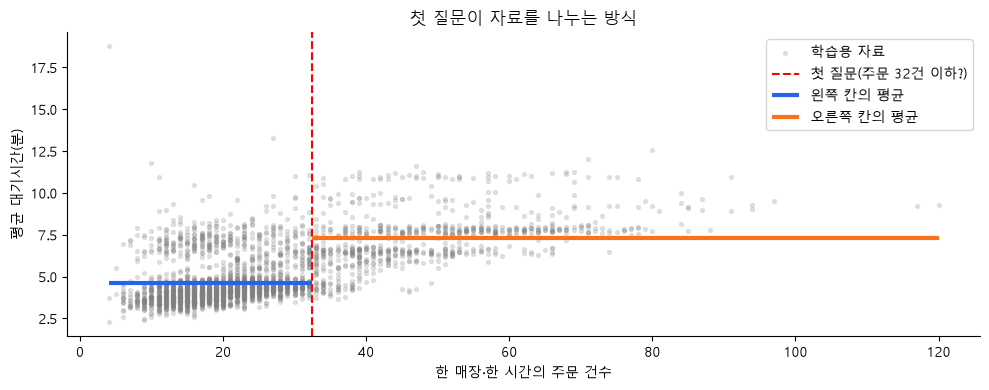

In [22]:
limit = 32.5
is_left = X_train["orders"] <= limit
left_mean = y_train[is_left].mean()
right_mean = y_train[~is_left].mean()

plt.scatter(X_train["orders"], y_train, s=8, alpha=0.2, color="gray", label="학습용 자료")
plt.axvline(limit, color="red", linestyle="--", label="첫 질문(주문 32건 이하?)")
plt.hlines(left_mean, X_train["orders"].min(), limit, color="#2563eb", linewidth=3, label="왼쪽 칸의 평균")
plt.hlines(right_mean, limit, X_train["orders"].max(), color="#f97316", linewidth=3, label="오른쪽 칸의 평균")
plt.title("첫 질문이 자료를 나누는 방식")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.legend()
plt.tight_layout()
plt.show()

### 의사결정나무 회귀

실제 모델은 질문을 3번까지 이어 가는 나무를 씁니다. 깊이가 한 단계 깊어지면 칸이 더 잘게 나뉩니다. `max_depth`는 질문을 이어 가는 최대 횟수입니다.

- `DecisionTreeRegressor(max_depth=3, random_state=0)`은 질문을 최대 3번까지 이어 가는 나무 모델을 만듭니다. `random_state=0`은 실행할 때마다 같은 결과가 나오게 합니다.
- `tree.fit(X_train, y_train)`은 학습용 입력과 정답에서 질문과 기준값을 찾습니다. 입력이 두 개여도 선형 회귀와 사용법이 같습니다.

In [23]:
tree = DecisionTreeRegressor(max_depth=3, random_state=0)
tree.fit(X_train, y_train)
print("학습을 마쳤습니다.")

학습을 마쳤습니다.


`fit()`이 학습한 질문을 `plot_tree()` 그림으로 확인합니다. 앞의 나무와 같은 구조이며, 깊이가 한 단계 더 깊습니다.

- `feature_names`는 질문에 쓰인 입력 열의 이름, `filled=True`는 예측값에 따라 칸을 색칠, `fontsize`는 글자 크기, `precision=1`은 소수 첫째 자리까지 나타냅니다.
- 각 칸의 첫 줄이 질문이고, 답이 "예"이면(`True`) 왼쪽, "아니오"이면(`False`) 오른쪽 칸으로 갑니다. `samples`는 그 칸에 도착한 학습용 시간대의 수, `value`는 그 칸의 **평균 대기시간(예측값)**입니다. `squared_error`는 칸 안의 값들이 흩어진 정도입니다.
- `plt.figure(figsize=(가로, 세로))`는 그림의 크기를 정합니다.

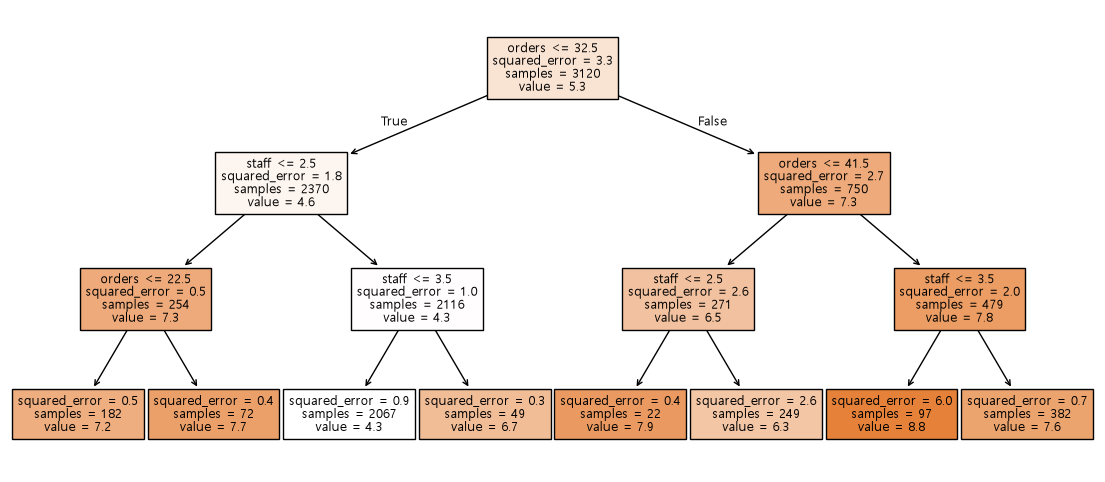

In [24]:
plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=["orders", "staff"], filled=True, fontsize=9, precision=1)
plt.show()

- `tree.predict(X_test)`는 평가용 입력 전체의 예측값을 계산합니다. 평가용 정답은 모델에 주지 않습니다.
- `mean_absolute_error(y_test, 예측값)`으로 평균 오차를 구해 앞의 결과와 비교합니다.

In [25]:
tree_error = mean_absolute_error(y_test, tree.predict(X_test))
print("선형 회귀(주문 건수와 직원 수):", round(model_two_error, 2), "분")
print("의사결정나무(깊이 3):", round(tree_error, 2), "분")

선형 회귀(주문 건수와 직원 수): 0.93 분
의사결정나무(깊이 3): 0.66 분


의사결정나무의 평균 오차는 0.66분으로, 같은 입력을 쓴 선형 회귀의 0.93분보다 작습니다. 이 자료에서는 주문이 많아질수록 대기가 직선으로 늘기보다 구간마다 다른 값을 보이기 때문에, 구간별로 값을 정하는 나무가 더 잘 맞습니다.

의사결정나무는 입력의 단위가 달라도 그대로 쓸 수 있고, 질문을 그림으로 읽을 수 있다는 장점이 있습니다. 반면 깊이가 깊어지면 학습용 자료에 지나치게 맞춰지므로, 다음에서 깊이를 조정합니다.

### 나무의 깊이 조정

모델을 만들 때 직접 지정하는 값을 **설정값**이라고 합니다. 나무의 설정값인 `max_depth`는 질문을 이어 가는 최대 횟수입니다. 깊이가 얕으면 자료를 거칠게 나누고, 깊으면 학습용 자료를 세밀하게 따라갑니다. 깊이를 바꿔 가며 학습용 자료의 오차와 평가용 자료의 오차를 함께 계산합니다.

- `depths`는 시험해 볼 깊이의 목록이고, `None`은 깊이를 제한하지 않는다는 뜻입니다.
- `for depth in depths:`는 깊이를 하나씩 바꿔 아래 줄들을 반복합니다. 반복마다 나무를 학습하고, 학습용 오차와 평가용 오차를 계산해 `append()`로 목록 끝에 추가합니다.
- 마지막에 `pd.DataFrame`으로 깊이별 오차를 표로 묶습니다.

In [26]:
depths = [1, 2, 3, 4, 5, 10, None]
train_errors, test_errors = [], []
for depth in depths:
    candidate = DecisionTreeRegressor(max_depth=depth, random_state=0)
    candidate.fit(X_train, y_train)
    train_errors.append(mean_absolute_error(y_train, candidate.predict(X_train)))
    test_errors.append(mean_absolute_error(y_test, candidate.predict(X_test)))

pd.DataFrame({
    "나무의 깊이": ["1", "2", "3", "4", "5", "10", "제한 없음"],
    "학습용 평균 오차(분)": train_errors,
    "평가용 평균 오차(분)": test_errors,
}).round(2)

,나무의 깊이,학습용 평균 오차(분),평가용 평균 오차(분)
0,1,1.03,1.00
1,2,0.72,0.72
2,3,0.67,0.66
3,4,0.61,0.62
4,5,0.60,0.62
5,10,0.58,0.64
6,제한 없음,0.58,0.64


깊이를 늘릴수록 학습용 오차는 1.03분에서 0.58분까지 계속 줄어듭니다. 평가용 오차는 깊이 5에서 0.62분으로 가장 작고, 깊이 10부터는 0.64분으로 다시 커집니다. 나무가 지나치게 깊으면 학습용 자료에만 지나치게 맞춰져 새로운 자료에서는 오히려 더 틀리는데, 이 상태를 **과적합**이라고 합니다. 그래서 설정값은 학습용 자료가 아니라 **평가용 자료의 오차**를 보고 고릅니다.

깊이 5의 나무로 다시 학습하고 평균 오차를 구합니다.

In [27]:
best_tree = DecisionTreeRegressor(max_depth=5, random_state=0)
best_tree.fit(X_train, y_train)
best_tree_error = mean_absolute_error(y_test, best_tree.predict(X_test))
print("의사결정나무(깊이 5):", round(best_tree_error, 2), "분")

의사결정나무(깊이 5): 0.62 분


깊이를 3에서 5로 바꾸자 평균 오차가 0.66분에서 0.62분으로 줄었습니다.

### 랜덤 포레스트의 원리

나무 한 그루에는 약점이 있습니다. 학습용 자료가 조금만 달라져도 질문이 바뀌고, 그에 따라 예측도 달라집니다. 한 그루의 답만 믿으면 우연히 치우친 답을 얻을 수 있습니다.

**랜덤 포레스트**는 나무를 여러 그루 만들어 각 나무의 예측을 **평균**하는 모델입니다. 나무가 모인 숲(forest)이라는 뜻의 이름입니다. 똑같은 나무를 100그루 만들면 평균을 내도 달라지는 것이 없으므로, 나무마다 **서로 다른 자료**로 학습시킵니다. 방법은 학습용 자료에서 시간대를 무작위로 다시 뽑는 것입니다.

| 뽑은 자료 | 만드는 방법 | 학습하는 나무 |
|---|---|---|
| 자료 1 | 학습용 시간대에서 전체 개수만큼 무작위로 뽑음 | 나무 1 |
| 자료 2 | 같은 방법으로 다시 뽑음 | 나무 2 |
| … | … | … |
| 자료 100 | 같은 방법으로 다시 뽑음 | 나무 100 |

한 번 뽑은 시간대는 다시 넣고 뽑습니다. 그래서 같은 시간대가 한 자료에 여러 번 들어가기도 하고, 한 번도 들어가지 않기도 합니다. 학습용 자료 전체 개수만큼 뽑았을 때 서로 다른 시간대가 얼마나 들어가는지 확인합니다.

- `np.random.default_rng(0)`은 무작위 수를 만드는 도구이고, `rng.integers(0, 개수, size=개수)`는 0부터 개수 미만의 번호를 개수만큼 무작위로 뽑습니다. 같은 번호가 다시 나올 수 있습니다.
- `set(picked)`는 겹치는 번호를 하나로 합쳐 서로 다른 번호만 남깁니다.

In [28]:
rng = np.random.default_rng(0)
picked = rng.integers(0, len(X_train), size=len(X_train))

different = len(set(picked))
print("뽑은 횟수:", len(picked))
print("서로 다른 시간대:", different, "개")
print("학습용 자료 전체에서 차지하는 비율:", round(different / len(X_train) * 100), "%")

뽑은 횟수: 3120
서로 다른 시간대: 1943 개
학습용 자료 전체에서 차지하는 비율: 62 %


뽑은 자료에는 학습용 시간대의 약 62%만 들어갑니다. 나무마다 들어가는 시간대가 달라서 질문과 기준값도 조금씩 달라집니다. 예측할 때는 모든 나무에 같은 입력을 물어보고, 나무들이 낸 예측을 평균합니다.

### 랜덤 포레스트 회귀

- `RandomForestRegressor(n_estimators=100, max_depth=5, random_state=0)`은 나무 100그루로 이루어진 숲을 만듭니다. `n_estimators`는 나무의 수이고, `max_depth`는 나무 한 그루의 깊이입니다. 앞에서 고른 깊이 5를 씁니다.
- 사용법은 다른 모델과 같습니다. `fit()`으로 학습하고 `predict()`로 예측합니다.

In [29]:
forest = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=0)
forest.fit(X_train, y_train)
forest_error = mean_absolute_error(y_test, forest.predict(X_test))
print("랜덤 포레스트(나무 100그루):", round(forest_error, 2), "분")

랜덤 포레스트(나무 100그루): 0.61 분


평균 오차는 0.61분으로 깊이 5의 나무 한 그루(0.62분)보다 조금 작습니다. 랜덤 포레스트가 답을 내는 과정을 새로운 시간대 하나(주문 45건, 직원 3명)로 확인합니다.

숲 안의 나무 몇 그루가 낸 예측과, 100그루 전체의 평균은 다음과 같습니다.

| 나무 | 주문 45건, 직원 3명인 시간대의 예측 |
|---|---|
| 나무 1 | 7.0분 |
| 나무 2 | 7.2분 |
| 나무 3 | 8.2분 |
| … | … |
| 나무 100 | 7.2분 |
| **100그루의 평균** | **7.6분** |

나무마다 예측이 다릅니다. 나무 1은 7.0분, 나무 2는 7.2분, 나무 3은 8.2분으로 예측했고, 이 값들을 평균한 7.6분이 랜덤 포레스트의 예측입니다. 100그루가 낸 예측이 얼마나 흩어져 있는지 히스토그램으로 확인합니다.

- `new_slot`은 주문 45건, 직원 3명인 시간대 하나짜리 입력 표입니다.
- `[one.predict(new_slot.values)[0] for one in forest.estimators_]`는 나무 100그루가 낸 예측을 목록으로 모읍니다.
- `plt.hist(값들, bins=15)`는 값을 15개 구간으로 나누어 구간마다 몇 개가 있는지 막대로 그립니다.

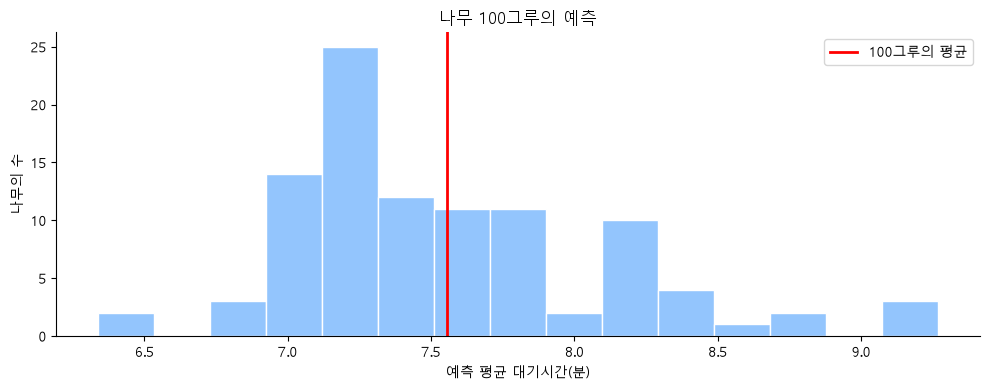

In [30]:
new_slot = pd.DataFrame({"orders": [45], "staff": [3]})
tree_predictions = [one.predict(new_slot.values)[0] for one in forest.estimators_]

plt.hist(tree_predictions, bins=15, color="#93c5fd", edgecolor="white")
plt.axvline(np.mean(tree_predictions), color="red", linewidth=2, label="100그루의 평균")
plt.title("나무 100그루의 예측")
plt.xlabel("예측 평균 대기시간(분)")
plt.ylabel("나무의 수")
plt.legend()
plt.tight_layout()
plt.show()

나무 한 그루의 예측은 6.3분에서 9.3분까지 흩어져 있습니다. 한 그루만 쓰면 이 가운데 어느 값이 나올지 알 수 없지만, 100그루를 평균하면 가운데 값인 7.6분이 됩니다. 한 그루의 우연한 치우침이 평균에서 줄어드는 것이 랜덤 포레스트가 나무 한 그루보다 흔들림이 적은 이유입니다.

### 모델 비교

지금까지 만든 모델의 평균 오차를 한 표로 모읍니다.

- `pd.DataFrame({"열 이름": 목록, ...})`으로 모델별 평균 오차를 표 하나로 모읍니다.
- `.round(2)`는 소수 둘째 자리까지 나타냅니다.

In [31]:
comparison = pd.DataFrame({
    "모델": ["선형 회귀(주문 건수)", "선형 회귀(주문 건수, 직원 수)", "의사결정나무(깊이 3)",
           "의사결정나무(깊이 5)", "랜덤 포레스트(나무 100그루)"],
    "평균 오차(분)": [model_one_error, model_two_error, tree_error, best_tree_error, forest_error],
}).round(2)
comparison

,모델,평균 오차(분)
0,선형 회귀(주문 건수),0.97
1,"선형 회귀(주문 건수, 직원 수)",0.93
2,의사결정나무(깊이 3),0.66
3,의사결정나무(깊이 5),0.62
4,랜덤 포레스트(나무 100그루),0.61


평균 오차는 선형 회귀 0.97분(주문 건수만)에서 0.93분(직원 수 추가), 의사결정나무 0.66분(깊이 3)에서 0.62분(깊이 5), 랜덤 포레스트 0.61분으로 줄었습니다. 입력을 늘리고, 모델을 바꾸고, 설정을 고르는 순서로 성능이 개선되었습니다.

모델이 주문 건수에 따라 어떻게 예측하는지 그림으로 비교합니다. 직원 수는 3명으로 고정하고, 주문 건수를 5건부터 60건까지 바꿔 가며 세 모델의 예측값을 선으로 그립니다.

- `np.arange(5, 61)`은 5부터 60까지의 정수를 나열합니다.
- `pd.DataFrame({"orders": ..., "staff": 3})`은 주문 건수가 5~60이고 직원이 모두 3명인 입력 표를 만듭니다.
- `X_train["staff"] == 3`은 직원이 3명인 학습용 시간대만 고르는 조건입니다. 같은 조건으로 점을 그려 모델의 선과 비교합니다.

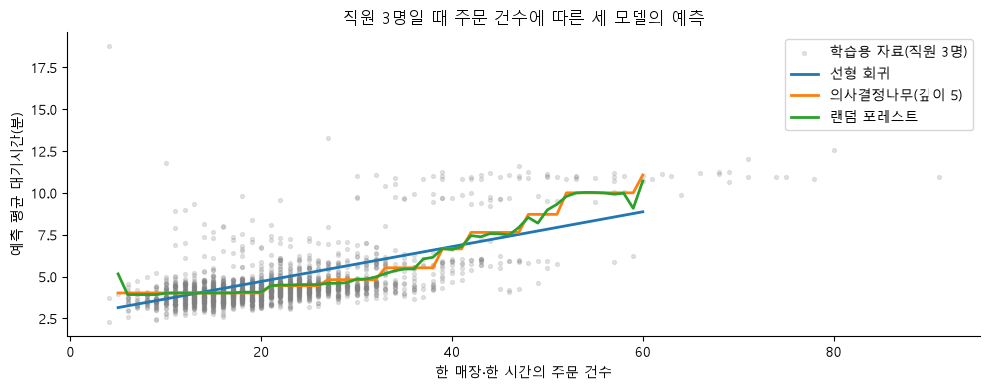

In [32]:
grid = pd.DataFrame({"orders": np.arange(5, 61), "staff": 3})
three = X_train["staff"] == 3

plt.scatter(X_train.loc[three, "orders"], y_train[three], s=8, alpha=0.2, color="gray", label="학습용 자료(직원 3명)")
plt.plot(grid["orders"], model_two.predict(grid), linewidth=2, label="선형 회귀")
plt.plot(grid["orders"], best_tree.predict(grid), linewidth=2, label="의사결정나무(깊이 5)")
plt.plot(grid["orders"], forest.predict(grid), linewidth=2, label="랜덤 포레스트")
plt.title("직원 3명일 때 주문 건수에 따른 세 모델의 예측")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("예측 평균 대기시간(분)")
plt.legend()
plt.tight_layout()
plt.show()

선형 회귀(직선)는 주문이 늘수록 일정한 비율로 예측값이 오릅니다. 의사결정나무는 기준값을 넘을 때마다 값이 계단처럼 바뀝니다. 랜덤 포레스트는 여러 나무의 계단을 평균해 계단이 더 잘게 나뉩니다. 같은 자료에서 모델마다 예측하는 방식이 다르고, 자료의 모양에 따라 잘 맞는 모델이 달라집니다.

## 6단계 예측과 활용

### 새로운 입력에 대한 예측

선택한 모델에 아직 보지 못한 시간대를 주고 예측하게 합니다. 한 매장에서 한 시간 동안 주문이 45건 들어오고 직원이 3명인 시간대입니다. 모델을 실제로 활용하는 것은 이렇게 정답을 모르는 새 입력으로 `predict()`를 하는 일입니다.

- `new_slot`은 앞에서 만든 시간대 하나짜리 입력 표입니다.
- `predict()`는 결과를 목록으로 돌려주므로 `[0]`으로 첫 값을 꺼냅니다.

In [33]:
print("선형 회귀:", round(model_two.predict(new_slot)[0], 1), "분")
print("의사결정나무(깊이 5):", round(best_tree.predict(new_slot)[0], 1), "분")
print("랜덤 포레스트:", round(forest.predict(new_slot)[0], 1), "분")

선형 회귀: 7.3 분
의사결정나무(깊이 5): 7.6 분
랜덤 포레스트: 7.6 분


같은 입력을 보고 선형 회귀는 약 7.3분, 의사결정나무는 약 7.6분, 랜덤 포레스트는 약 7.6분으로 예측했습니다. 정답을 모르는 상황에서는 한 모델의 숫자를 그대로 믿기보다, 앞에서 구한 평균 오차(약 0.6분)를 함께 보고 대략적인 범위로 해석합니다. 이 평균 오차는 여러 시간대에서 나온 평균적인 차이이므로, 방금 예측한 값에 더하고 빼면 되는 보장 범위는 아닙니다. 또 45건은 앞으로 들어올 주문량을 가정한 값이어서, 실제 주문량이 다르면 대기시간도 달라집니다.

### 예측이 크게 틀린 시간대 살펴보기

평균 오차 하나만으로는 크게 틀린 사례가 가려집니다. 산점도에서 전체 경향을 벗어난 점의 원자료를 확인하듯이, 평가용 자료에서 랜덤 포레스트가 크게 틀린 시간대를 찾아봅니다.

- `slot.loc[X_test.index, [...]]`는 평가용 입력의 행 번호로 `slot`에서 날짜·매장·시간대와 입력·정답 열을 가져옵니다.
- `check["절대오차"]`는 실제 대기시간과 예측값의 차이에서 부호를 없앤 값입니다.
- `sort_values("절대오차", ascending=False)`는 오차가 큰 순서로 정렬하고, `head(5)`는 앞 5행을 고릅니다.

In [34]:
big_miss = slot.loc[X_test.index, ["order_date", "store_location", "order_hour", "orders", "staff", "wait"]].copy()
big_miss["예측"] = forest.predict(X_test)
big_miss["절대오차"] = (big_miss["wait"] - big_miss["예측"]).abs()
big_miss.sort_values("절대오차", ascending=False).head(5).round(2)

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_358640\2039385158.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  big_miss.sort_values("절대오차", ascending=False).head(5).round(2)


,order_date,store_location,order_hour,orders,staff,wait,예측,절대오차
1603,2026-05-14,도서관점,12,33,3.0,10.93,5.18,5.75
1300,2026-04-30,도서관점,9,10,3.0,9.70,4.01,5.69
3344,2026-08-04,도서관점,13,29,3.0,9.72,4.64,5.08
3513,2026-08-12,공학관점,12,40,3.0,11.32,6.63,4.70
3649,2026-08-18,도서관점,18,4,3.0,3.88,8.27,4.39


가장 크게 틀린 5개 시간대 가운데 4개는 실제 대기시간이 예측보다 길었습니다. 주문량과 직원 수만으로는 예측하기 어려운 시간대입니다. 오차가 크다는 이유만으로 기록 오류라고 판단하지 않습니다. 메뉴 구성이나 행사처럼 입력에 넣지 않은 조건, 원자료에 있는 큰 대기시간 한 건 등이 관련되는지 원자료를 확인해 볼 수 있습니다. 평가용 780개 시간대 가운데 오차가 3분 이상인 시간대는 12개로, 대부분의 시간대에서는 평균 0.6분 안팎으로 맞습니다.

### 회귀 모델 구축 절차의 요약

회귀 모델을 만든 과정을 코드 하나로 모으면 다음과 같습니다. 앞에서 한 일이 여섯 단계의 순서대로 놓여 있습니다. 모델을 바꾸려면 3단계의 `LinearRegression()`만 `DecisionTreeRegressor(max_depth=5)`나 `RandomForestRegressor(max_depth=5)`로 바꾸면 됩니다.

In [35]:
# 1단계 문제 정의: 입력은 주문 건수와 직원 수, 맞힐 값은 평균 대기시간
X = slot[["orders", "staff"]]
y = slot["wait"]

# 2단계 자료 준비: 학습용과 평가용으로 나누기
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 3단계 모델 학습
model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=0)
model.fit(X_train, y_train)

# 4단계 모델 평가
predicted = model.predict(X_test)
print("평균 오차:", round(mean_absolute_error(y_test, predicted), 2), "분")

# 5단계 성능 개선: 위의 3단계 모델을 바꾸거나 설정값을 바꿔 3~4단계를 반복

# 6단계 예측과 활용: 새 입력으로 예측
print("새 시간대의 예측:", round(model.predict(new_slot)[0], 1), "분")

평균 오차: 0.61 분
새 시간대의 예측: 7.6 분


평균 오차는 0.61분으로 앞에서 랜덤 포레스트로 구한 결과와 같습니다.

## 분석 결과의 정리

| 질문 | 모델 | 평가용 자료의 결과 |
|---|---|---|
| 주문 건수와 직원 수로 평균 대기시간을 예측할 수 있는가? | 선형 회귀 | 평균 오차 0.93분 |
| 모델 종류에 따라 결과가 달라지는가? | 선형 회귀, 의사결정나무(깊이 5), 랜덤 포레스트 | 평균 오차 0.93분, 0.62분, 0.61분 |
| 설정값에 따라 결과가 달라지는가? | 깊이가 다른 의사결정나무 | 깊이 3은 0.66분, 깊이 5는 0.62분, 깊이 제한 없음은 0.64분 |
| 학습용 자료에만 맞춘 모델은 새 자료에서도 좋은가? | 깊이 제한이 없는 의사결정나무 | 학습용 0.58분, 평가용 0.64분 |

다음은 표를 근거로 작성할 수 있는 결론의 예입니다.

> 이 자료에서는 한 매장·한 시간의 주문 건수와 직원 수로 평균 대기시간을 평균 약 0.6~0.9분의 오차로 예측할 수 있습니다. 구간별로 값을 정하는 의사결정나무와 랜덤 포레스트가 직선인 선형 회귀보다 오차가 작았고, 나무의 깊이를 조정하면 오차를 더 줄일 수 있었습니다. 다만 모델은 입력과 결과가 함께 움직이는 규칙을 학습한 것이어서 직원을 늘리면 대기시간이 줄어든다는 인과를 확정하지 못합니다. 다른 매장이나 다른 기간에 적용하려면 그 자료로 다시 학습하고 평가해야 합니다.

인공지능의 모델은 **자료에서 입력과 결과 사이의 규칙을 학습해, 보지 못한 입력에 적용하는 방법**입니다. 규칙은 학습용 자료로 학습하고, 좋은 규칙인지는 평가용 자료로 판단합니다. 모델이 낸 예측은 정답이 아니라 근거가 있는 추정이므로, 오차의 크기와 학습한 범위, 자료의 한계를 함께 밝혀 해석합니다.